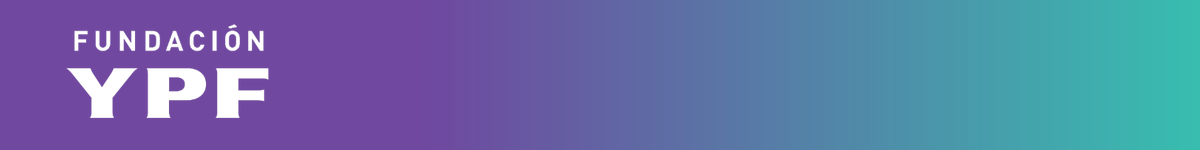


# Fundación YPF - Data Science

## Notebook 31: Perceptrón multicapa en profundidad: funciones de activación y regularización

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: perceptrón simple, forward propagation y backpropagation
* **Parte 2:** Perceptrón multicapa con scikit-learn y funciones de activación
* **Parte 3:** Arquitectura de la red: capas, neuronas y overfitting
* **Parte 4:** Regularización: L2 (alpha) y early stopping
* **Parte 5:** Tasa de aprendizaje y curvas de entrenamiento
* **Parte 6:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En la clase anterior (perceptrón simple y multicapa) vimos forward propagation, backpropagation y una primera mención a las funciones de activación disponibles (sigmoidea, tanh, ReLU y Leaky ReLU). Hoy profundizamos ese tema: comparamos esas funciones de activación entrenando un perceptrón multicapa de verdad, vemos cómo la arquitectura de la red (cantidad de capas y de neuronas) puede llevar a overfitting, y cómo mitigarlo con regularización (alpha) y early stopping. Cerramos con el efecto de la tasa de aprendizaje sobre el entrenamiento.

**Dataset:** `cancer_mamario.csv`: historias clínicas de pacientes con cáncer de mama, con la variable `class` que indica si hubo o no recurrencia del evento. Es un problema de clasificación binaria con variables mayormente categóricas, apropiado para entrenar un perceptrón multicapa con `MLPClassifier`.

Antes de ejecutar, subí el archivo `cancer_mamario.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: perceptrón simple, forward propagation y backpropagation

Antes de pasar al perceptrón multicapa con scikit-learn, repasamos a mano una sola neurona sigmoidea: calculamos `z` (unión sumadora), aplicamos la función de activación (forward propagation) y medimos el error con entropía cruzada, igual que en la clase anterior.

In [2]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def entropia_cruzada(y, y_pred, eps=1e-9):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))

# Una instancia de ejemplo con 2 features (x1, x2) y pesos ya "entrenados"
x = np.array([0.6, -1.2])
w = np.array([1.5, 0.8])
w0 = -0.3
y_real = 1

z = w0 + np.dot(w, x)
y_pred = sigmoide(z)
costo = entropia_cruzada(y_real, y_pred)

print(f"z = {z:.3f}")
print(f"Prediccion (forward propagation): {y_pred:.3f}")
print(f"Costo (entropia cruzada) para esta instancia: {costo:.3f}")

z = -0.360
Prediccion (forward propagation): 0.411
Costo (entropia cruzada) para esta instancia: 0.889


## Parte 2: Perceptrón multicapa con scikit-learn y funciones de activación

Cargamos el dataset, lo preprocesamos y entrenamos un `MLPClassifier` con una capa oculta, comparando las funciones de activación que vimos en la teoría: `relu`, `tanh` y `logistic` (sigmoidea).

In [3]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

datos = pd.read_csv("cancer_mamario.csv")
print("Filas:", len(datos))
datos.head()

Filas: 286


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [4]:
print(datos["class"].value_counts())
print()
print("Valores '?' por columna:")
print((datos == "?").sum())

class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64

Valores '?' por columna:
class          0
age            0
menopause      0
tumor-size     0
inv-nodes      0
node-caps      8
deg-malig      0
breast         0
breast-quad    1
irradiat       0
dtype: int64


Las columnas `node-caps` y `breast-quad` tienen algunos valores `?` que tratamos como faltantes. La variable `class` está desbalanceada (hay más casos sin recurrencia que con recurrencia), así que usamos `stratify` al separar en train y test para mantener esa proporción en ambos conjuntos.

In [5]:
datos_limpios = datos.replace("?", np.nan)

X = datos_limpios.drop(columns=["class"])
y = (datos_limpios["class"] == "recurrence-events").astype(int)

columnas_categoricas = X.select_dtypes(include="object").columns.tolist()
columnas_numericas = X.select_dtypes(exclude="object").columns.tolist()
print("Categoricas:", columnas_categoricas)
print("Numericas:", columnas_numericas)

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), columnas_numericas),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), columnas_categoricas),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Categoricas: ['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps', 'breast', 'breast-quad', 'irradiat']
Numericas: ['deg-malig']
Train: (214, 9) Test: (72, 9)


In [6]:
activaciones = ["relu", "tanh", "logistic"]
resultados_activacion = []

for act in activaciones:
    modelo = Pipeline([
        ("prep", preprocesador),
        ("mlp", MLPClassifier(hidden_layer_sizes=(16,), activation=act,
                               max_iter=2000, random_state=RANDOM_STATE)),
    ])
    modelo.fit(X_train, y_train)
    acc_train = accuracy_score(y_train, modelo.predict(X_train))
    acc_test = accuracy_score(y_test, modelo.predict(X_test))
    resultados_activacion.append({"activacion": act, "accuracy_train": acc_train, "accuracy_test": acc_test})

tabla_activaciones = pd.DataFrame(resultados_activacion)
tabla_activaciones

,activacion,accuracy_train,accuracy_test
0,relu,0.939252,0.638889
1,tanh,0.929907,0.638889
2,logistic,0.789720,0.708333


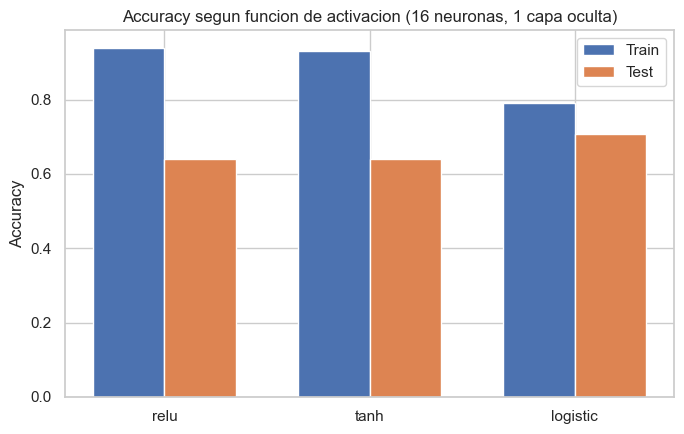

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x_pos = np.arange(len(tabla_activaciones))
ancho = 0.35
ax.bar(x_pos - ancho / 2, tabla_activaciones["accuracy_train"], ancho, label="Train")
ax.bar(x_pos + ancho / 2, tabla_activaciones["accuracy_test"], ancho, label="Test")
ax.set_xticks(x_pos)
ax.set_xticklabels(tabla_activaciones["activacion"])
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy segun funcion de activacion (16 neuronas, 1 capa oculta)")
ax.legend()
plt.tight_layout()
plt.show()

La comparación anterior usa una arquitectura chica (una sola capa de 16 neuronas), donde las tres funciones de activación entrenan sin mayores problemas. De acá en adelante usamos `relu` para las arquitecturas más profundas de las próximas partes: como vimos en la teoría, la sigmoidea sufre vanishing gradient y convergencia lenta a medida que la red crece, mientras que ReLU fue pensada justamente para mitigar ese problema en redes más profundas.

In [8]:
activacion_elegida = "relu"

## Parte 3: Arquitectura de la red: capas, neuronas y overfitting

Usamos `relu` como función de activación y probamos arquitecturas cada vez más grandes (más neuronas y más capas ocultas), para ver cómo cambia la brecha entre el accuracy de train y el de test: esa brecha creciente es la señal de overfitting.

In [9]:
arquitecturas = [(4,), (16,), (64,), (64, 32), (128, 64, 32)]
resultados_arq = []

for arq in arquitecturas:
    modelo = Pipeline([
        ("prep", preprocesador),
        ("mlp", MLPClassifier(hidden_layer_sizes=arq, activation=activacion_elegida,
                               max_iter=3000, random_state=RANDOM_STATE)),
    ])
    modelo.fit(X_train, y_train)
    mlp_entrenado = modelo.named_steps["mlp"]
    n_parametros = sum(c.size for c in mlp_entrenado.coefs_) + sum(b.size for b in mlp_entrenado.intercepts_)
    acc_train = accuracy_score(y_train, modelo.predict(X_train))
    acc_test = accuracy_score(y_test, modelo.predict(X_test))
    resultados_arq.append({
        "arquitectura": str(arq),
        "parametros": n_parametros,
        "accuracy_train": acc_train,
        "accuracy_test": acc_test,
    })

tabla_arq = pd.DataFrame(resultados_arq)
tabla_arq

,arquitectura,parametros,accuracy_train,accuracy_test
0,"(4,)",161,0.864486,0.694444
1,"(16,)",641,0.939252,0.638889
2,"(64,)",2561,0.971963,0.638889
3,"(64, 32)",4609,0.971963,0.625000
4,"(128, 64, 32)",15361,0.976636,0.597222


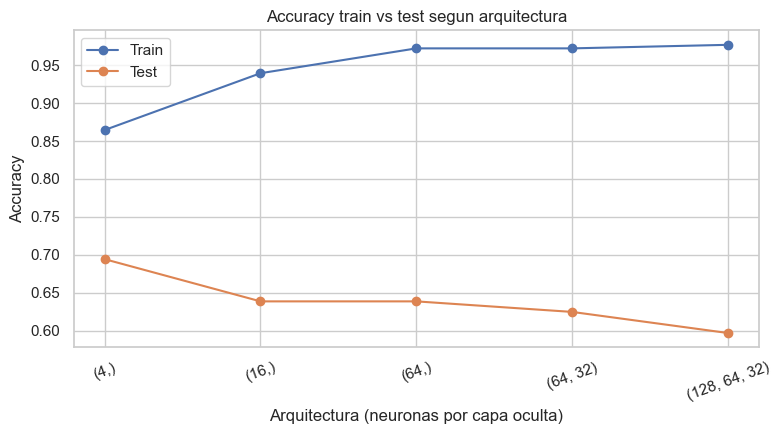

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla_arq["arquitectura"], tabla_arq["accuracy_train"], marker="o", label="Train")
ax.plot(tabla_arq["arquitectura"], tabla_arq["accuracy_test"], marker="o", label="Test")
ax.set_xlabel("Arquitectura (neuronas por capa oculta)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy train vs test segun arquitectura")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Parte 4: Regularización: L2 (alpha) y early stopping

`scikit-learn` no tiene una capa de Dropout como Keras o PyTorch (esa implementación es propia de esos frameworks de deep learning), pero el `MLPClassifier` sí ofrece dos formas de regularizar que persiguen el mismo objetivo que vimos en la teoría, penalizar la complejidad del modelo: el parámetro `alpha` (regularización L2, igual que la que penaliza pesos grandes en la función de costo) y `early_stopping`, que corta el entrenamiento cuando deja de mejorar en un conjunto de validación interno. Tomamos la arquitectura más grande de la Parte 3, la que más sobreajustaba, y probamos distintos valores de `alpha`.

In [11]:
arquitectura_grande = arquitecturas[-1]
valores_alpha = [0.0001, 0.001, 0.01, 0.1, 1.0]
resultados_alpha = []

for alpha in valores_alpha:
    modelo = Pipeline([
        ("prep", preprocesador),
        ("mlp", MLPClassifier(hidden_layer_sizes=arquitectura_grande, activation=activacion_elegida,
                               alpha=alpha, max_iter=3000, random_state=RANDOM_STATE)),
    ])
    modelo.fit(X_train, y_train)
    acc_train = accuracy_score(y_train, modelo.predict(X_train))
    acc_test = accuracy_score(y_test, modelo.predict(X_test))
    resultados_alpha.append({"alpha": alpha, "accuracy_train": acc_train, "accuracy_test": acc_test})

tabla_alpha = pd.DataFrame(resultados_alpha)
tabla_alpha

,alpha,accuracy_train,accuracy_test
0,0.0001,0.976636,0.597222
1,0.0010,0.976636,0.583333
2,0.0100,0.976636,0.597222
3,0.1000,0.967290,0.666667
4,1.0000,0.799065,0.722222


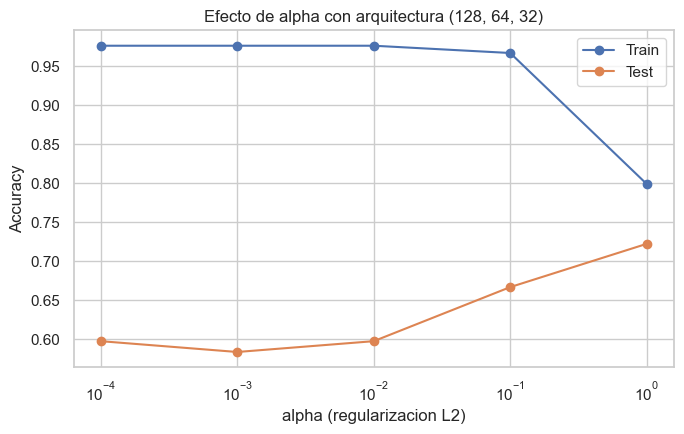

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tabla_alpha["alpha"], tabla_alpha["accuracy_train"], marker="o", label="Train")
ax.plot(tabla_alpha["alpha"], tabla_alpha["accuracy_test"], marker="o", label="Test")
ax.set_xscale("log")
ax.set_xlabel("alpha (regularizacion L2)")
ax.set_ylabel("Accuracy")
ax.set_title(f"Efecto de alpha con arquitectura {arquitectura_grande}")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
for early in (False, True):
    modelo = Pipeline([
        ("prep", preprocesador),
        ("mlp", MLPClassifier(hidden_layer_sizes=arquitectura_grande, activation=activacion_elegida,
                               early_stopping=early, max_iter=3000, random_state=RANDOM_STATE)),
    ])
    modelo.fit(X_train, y_train)
    acc_train = accuracy_score(y_train, modelo.predict(X_train))
    acc_test = accuracy_score(y_test, modelo.predict(X_test))
    n_iter = modelo.named_steps["mlp"].n_iter_
    print(f"early_stopping={early}: accuracy train={acc_train:.3f}, test={acc_test:.3f}, iteraciones={n_iter}")

early_stopping=False: accuracy train=0.977, test=0.597, iteraciones=164
early_stopping=True: accuracy train=0.729, test=0.639, iteraciones=14


## Parte 5: Tasa de aprendizaje y curvas de entrenamiento

La tasa de aprendizaje (`learning_rate_init`) controla qué tan grande es cada paso del descenso por gradiente. Entrenamos el mismo modelo con el solver `adam` variando la tasa de aprendizaje, y graficamos `loss_curve_` (la función de costo en cada iteración del entrenamiento).

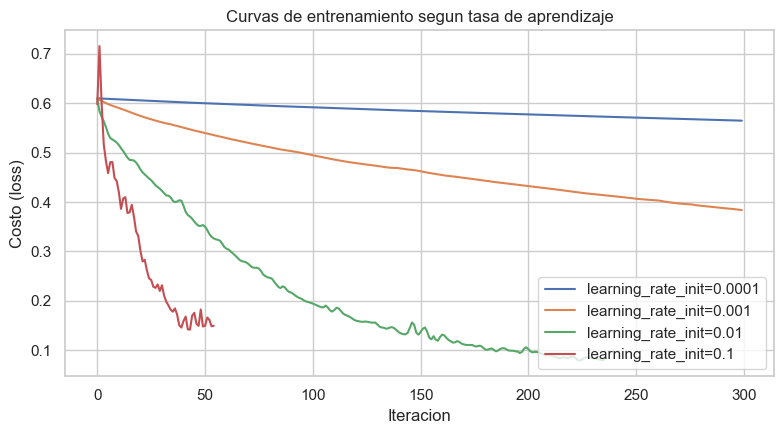

In [14]:
X_train_prep = preprocesador.fit_transform(X_train)

tasas = [0.0001, 0.001, 0.01, 0.1]
curvas = {}

for tasa in tasas:
    mlp = MLPClassifier(hidden_layer_sizes=(16,), activation=activacion_elegida,
                         solver="adam", learning_rate_init=tasa,
                         max_iter=300, random_state=RANDOM_STATE)
    mlp.fit(X_train_prep, y_train)
    curvas[tasa] = mlp.loss_curve_

fig, ax = plt.subplots(figsize=(8, 4.5))
for tasa, curva in curvas.items():
    ax.plot(curva, label=f"learning_rate_init={tasa}")
ax.set_xlabel("Iteracion")
ax.set_ylabel("Costo (loss)")
ax.set_title("Curvas de entrenamiento segun tasa de aprendizaje")
ax.legend()
plt.tight_layout()
plt.show()

Con una tasa de aprendizaje muy baja el costo baja muy despacio y el modelo puede no llegar a converger en pocas iteraciones. Con una tasa demasiado alta el descenso por gradiente puede oscilar en vez de acercarse de forma estable al mínimo. Elegir bien `learning_rate_init` es parte del mismo trabajo que elegir la arquitectura o la regularización: no hay un valor único que sirva para todos los problemas.

## Parte 6: Ejercicio para las salas de Zoom

**Dataset:** mismo `cancer_mamario.csv`. Reutilizamos `X_train`, `X_test`, `y_train`, `y_test`, `preprocesador` y `activacion_elegida` ya preparados arriba.

**Contexto:** en la Parte 3 vimos que las arquitecturas más grandes tienden a sobreajustar, y en la Parte 4 que `alpha` y `early_stopping` ayudan a controlar eso.

**Objetivo:** elegir su propia arquitectura y mostrar, con números propios, cómo la regularización mejora (o no) su capacidad de generalizar.

**Tiempo:** 45 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Arquitectura propia.** Elijan una arquitectura (`hidden_layer_sizes`) distinta a las de la Parte 3, entrenen un `MLPClassifier` y grafiquen su `loss_curve_`.
2. **Alpha bajo vs. alto.** Con esa misma arquitectura, comparen el accuracy de train y test usando un `alpha` bajo (por ejemplo 0.0001) y uno alto (por ejemplo 1.0).
3. **Early stopping.** Entrenen la misma arquitectura con `early_stopping=True` y comparen la cantidad de iteraciones (`n_iter_`) contra `early_stopping=False`.
4. **Comparación de activaciones.** Arme una tabla con el accuracy de test de `relu`, `tanh` y `logistic` para la arquitectura elegida.
5. **Conclusión.** ¿Qué combinación de arquitectura, alpha y función de activación generalizó mejor en su caso? Justifiquen con los números obtenidos.

In [15]:
# Variables ya disponibles: X_train, X_test, y_train, y_test, preprocesador, activacion_elegida, arquitecturas, valores_alpha

In [16]:
# 1. Arquitectura propia: entrenar y graficar su loss_curve_
# COMPLETAR

In [17]:
# 2. Comparar alpha bajo vs alpha alto con esa arquitectura
# COMPLETAR

In [18]:
# 3. Entrenar con early_stopping=True y comparar con early_stopping=False
# COMPLETAR

In [19]:
# 4. Tabla comparando accuracy de test de relu, tanh y logistic con su arquitectura
# COMPLETAR

In [20]:
# 5. Conclusion: que combinacion generalizo mejor y por que
# COMPLETAR